## 第一步：读取原始客流数据

In [1]:
from pathlib import Path

import pandas as pd

# Notebook 位于 notebook 文件夹，上一层是项目根目录
project_root = Path.cwd().parent
csv_path = (
    project_root / "data" / "raw" / "statistics_on_daily_passenger_traffic.csv"
)

raw_traffic = pd.read_csv(csv_path, encoding="utf-8-sig")
raw_traffic.columns = raw_traffic.columns.str.strip()

raw_dates = pd.to_datetime(
    raw_traffic["Date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce",
)

print("原始数据行数：", len(raw_traffic))
print("原始数据列数：", raw_traffic.shape[1])
print("列名：", raw_traffic.columns.tolist())
print("最早日期：", raw_dates.min())
print("最晚日期：", raw_dates.max())
print("缺失或无法解析的日期行数：", raw_dates.isna().sum())

display(raw_traffic.head())

原始数据行数： 63034
原始数据列数： 8
列名： ['Date', 'Control Point', 'Arrival / Departure', 'Hong Kong Residents', 'Mainland Visitors', 'Other Visitors', 'Total', 'Unnamed: 7']
最早日期： 2021-01-01 00:00:00
最晚日期： 2026-10-30 00:00:00
缺失或无法解析的日期行数： 0


,Date,Control Point,Arrival / Departure,Hong Kong Residents,Mainland Visitors,Other Visitors,Total,Unnamed: 7
0,01-01-2021,Airport,Arrival,341,0,9,350,NaN
1,01-01-2021,Airport,Departure,803,17,28,848,NaN
2,01-01-2021,Express Rail Link West Kowloon,Arrival,0,0,0,0,NaN
3,01-01-2021,Express Rail Link West Kowloon,Departure,0,0,0,0,NaN
4,01-01-2021,Hung Hom,Arrival,0,0,0,0,NaN


## 第二步：筛选深圳湾口岸入境记录

In [2]:
# 查看日期无法解析的原始行，判断是备注还是需要修正的记录
print("日期无法解析的原始行：")
display(raw_traffic.loc[raw_dates.isna()])

control_point = raw_traffic["Control Point"].astype("string").str.strip()
direction = raw_traffic["Arrival / Departure"].astype("string").str.strip()

is_shenzhen_bay = control_point.str.contains(
    "Shenzhen Bay", case=False, regex=False, na=False
)
is_arrival = direction.str.casefold().eq("arrival").fillna(False)

passenger_columns = [
    "Hong Kong Residents",
    "Mainland Visitors",
    "Other Visitors",
    "Total",
]

shenzhen_bay_arrivals = raw_traffic.loc[
    is_shenzhen_bay & is_arrival, ["Date", *passenger_columns]
].copy()

if shenzhen_bay_arrivals.empty:
    raise ValueError("没有找到深圳湾入境记录，请核对口岸名称和方向标签。")

shenzhen_bay_arrivals["Date"] = raw_dates.loc[shenzhen_bay_arrivals.index]

for column in passenger_columns:
    shenzhen_bay_arrivals[column] = pd.to_numeric(
        shenzhen_bay_arrivals[column], errors="coerce"
    )

shenzhen_bay_arrivals = (
    shenzhen_bay_arrivals.sort_values("Date").reset_index(drop=True)
)

valid_dates = pd.DatetimeIndex(shenzhen_bay_arrivals["Date"].dropna())
expected_dates = pd.date_range(valid_dates.min(), valid_dates.max(), freq="D")
missing_dates = expected_dates.difference(valid_dates)

complete_counts = shenzhen_bay_arrivals.dropna(subset=passenger_columns)
category_totals = complete_counts[passenger_columns[:3]].sum(axis=1)
total_mismatches = category_totals.ne(complete_counts["Total"]).sum()

print("匹配到的口岸名称：", control_point[is_shenzhen_bay].unique().tolist())
print("深圳湾入境记录数：", len(shenzhen_bay_arrivals))
print(f"日期范围：{valid_dates.min():%Y-%m-%d} 至 {valid_dates.max():%Y-%m-%d}")
print("筛选后日期无法解析的行数：", shenzhen_bay_arrivals["Date"].isna().sum())
print("重复日期的额外记录数：", valid_dates.duplicated().sum())
print("日期范围内缺失天数：", len(missing_dates))
print("客流字段缺失或无法转为数字的行数：",
      shenzhen_bay_arrivals[passenger_columns].isna().any(axis=1).sum())
print("三类旅客合计与 Total 不一致的行数：", total_mismatches)

if len(missing_dates) > 0:
    print("前 10 个缺失日期：", missing_dates[:10].strftime("%Y-%m-%d").tolist())

display(shenzhen_bay_arrivals.head())

日期无法解析的原始行：


,Date,Control Point,Arrival / Departure,Hong Kong Residents,Mainland Visitors,Other Visitors,Total,Unnamed: 7


匹配到的口岸名称： ['Shenzhen Bay']
深圳湾入境记录数： 2129
日期范围：2021-01-01 至 2026-10-30
筛选后日期无法解析的行数： 0
重复日期的额外记录数： 0
日期范围内缺失天数： 0
客流字段缺失或无法转为数字的行数： 0
三类旅客合计与 Total 不一致的行数： 0


,Date,Hong Kong Residents,Mainland Visitors,Other Visitors,Total
0,2021-01-01,346,43,1,390
1,2021-01-02,542,67,2,611
2,2021-01-03,798,38,2,838
3,2021-01-04,1311,64,2,1377
4,2021-01-05,703,69,1,773


## 第三步：整理并保存每日入境客流数据

In [3]:
# 统一列名，方便后续绘图和建模
daily_arrivals = shenzhen_bay_arrivals.rename(columns={
    "Date": "date",
    "Hong Kong Residents": "hong_kong_residents",
    "Mainland Visitors": "mainland_visitors",
    "Other Visitors": "other_visitors",
    "Total": "total_arrivals",
}).copy()

count_columns = [
    "hong_kong_residents",
    "mainland_visitors",
    "other_visitors",
    "total_arrivals",
]

counts = daily_arrivals[count_columns]
invalid_counts = counts.isna() | counts.lt(0) | counts.mod(1).ne(0)

if invalid_counts.any().any():
    display(daily_arrivals.loc[invalid_counts.any(axis=1)])
    raise ValueError("客流字段存在缺失、负数或非整数，请先检查上表。")

daily_arrivals[count_columns] = counts.astype("int64")

# 保存整理后的数据
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

output_path = processed_dir / "shenzhen_bay_daily_arrivals.csv"
daily_arrivals.to_csv(output_path, index=False, date_format="%Y-%m-%d")

print("保存记录数：", len(daily_arrivals))
print("已保存至：", output_path)

# 查看各年覆盖天数，识别数据只覆盖部分月份的年份
annual_coverage = (
    daily_arrivals.groupby(daily_arrivals["date"].dt.year)["date"]
    .agg(first_date="min", last_date="max", days="size")
    .rename_axis("year")
)

display(annual_coverage)

保存记录数： 2129
已保存至： d:\course\ds and ai\shenzhen-bay-passenger-forecast\data\processed\shenzhen_bay_daily_arrivals.csv


,first_date,last_date,days
year,,,
2021,2021-01-01,2021-12-31,365
2022,2022-01-01,2022-12-31,365
2023,2023-01-01,2023-12-31,365
2024,2024-01-01,2024-12-31,366
2025,2025-01-01,2025-12-31,365
2026,2026-01-01,2026-10-30,303


## 第四步：绘制深圳湾口岸每日入境客流趋势

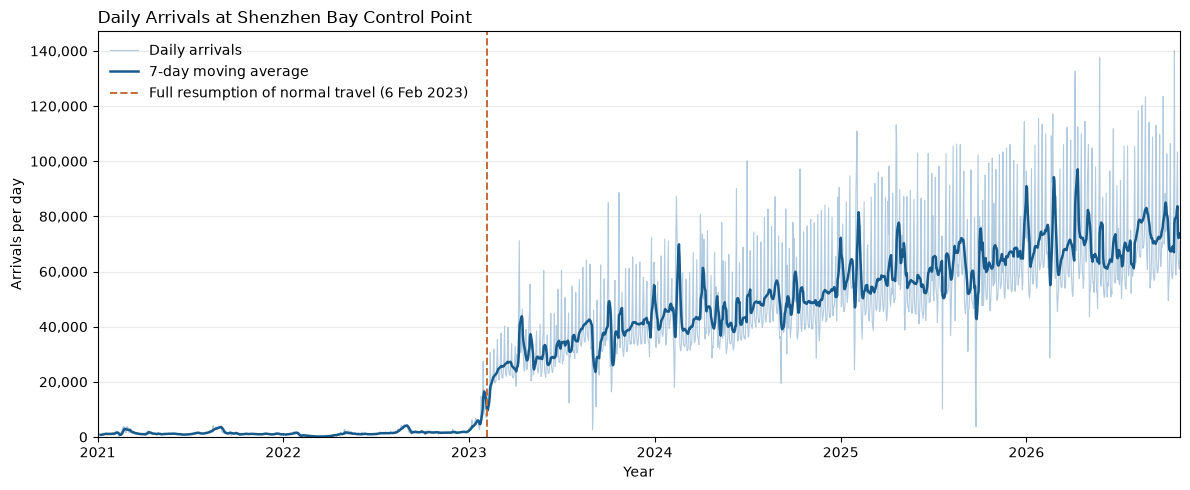

图表已保存至： d:\course\ds and ai\shenzhen-bay-passenger-forecast\figures\shenzhen_bay_daily_arrivals_trend.png


In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

# 按日期排序，计算截至当天的 7 日移动平均
trend_data = daily_arrivals.sort_values("date").copy()
trend_data["moving_average_7d"] = (
    trend_data["total_arrivals"].rolling(window=7, min_periods=7).mean()
)

reopening_date = pd.Timestamp("2023-02-06")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    trend_data["date"],
    trend_data["total_arrivals"],
    color="#93B5D2",
    linewidth=0.8,
    alpha=0.7,
    label="Daily arrivals",
)
ax.plot(
    trend_data["date"],
    trend_data["moving_average_7d"],
    color="#175A8C",
    linewidth=1.8,
    label="7-day moving average",
)
ax.axvline(
    reopening_date,
    color="#C46A35",
    linestyle="--",
    linewidth=1.4,
    label="Full resumption of normal travel (6 Feb 2023)",
)

ax.set_title("Daily Arrivals at Shenzhen Bay Control Point", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Arrivals per day")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(trend_data["date"].min(), trend_data["date"].max())
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left", frameon=False)

fig.tight_layout()

figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "shenzhen_bay_daily_arrivals_trend.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("图表已保存至：", figure_path)

## 第五步：比较年度客流水平和星期分布

,days,mean_daily_arrivals,median_daily_arrivals
year,,,
2021,365,1347.7,1159.0
2022,365,1329.4,1343.0
2023,365,31351.7,31038.0
2024,366,47634.1,43212.5
2025,365,61362.5,55281.0
2026,303,71407.2,64778.0


,days,mean_daily_arrivals,median_daily_arrivals
weekday,,,
Mon,152,46321.2,45991.0
Tue,152,40759.9,39578.5
Wed,152,40212.6,38813.5
Thu,151,40182.6,39556.0
Fri,151,43529.3,43403.0
Sat,151,54603.4,53653.0
Sun,151,71355.5,70700.0


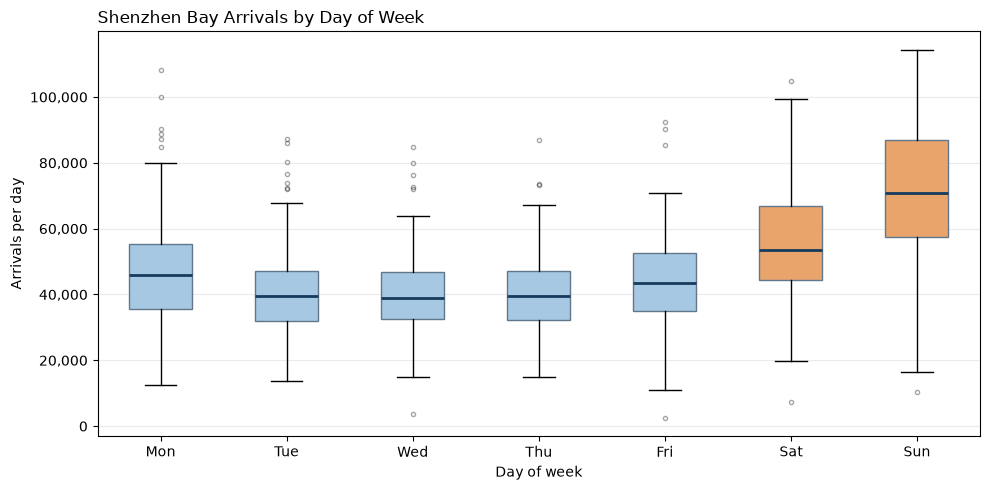

图表已保存至 d:\course\ds and ai\shenzhen-bay-passenger-forecast\figures\shenzhen_bay_arrivals_by_weekday.png


In [5]:
# 按年汇总。2026 年只覆盖至 10 月 30 日，因此同时显示覆盖天数
annual_summary = (
    daily_arrivals.groupby(daily_arrivals["date"].dt.year)["total_arrivals"]
    .agg(days="size", mean_daily_arrivals="mean", median_daily_arrivals="median")
    .rename_axis("year")
    .round(1)
)
display(annual_summary)

# 比较恢复正常通关后、最终测试期之前的星期分布
weekday_data = daily_arrivals.loc[
    daily_arrivals["date"].between("2023-02-06", "2025-12-31")
].copy()

weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday_data["weekday"] = weekday_data["date"].dt.dayofweek

weekday_summary = (
    weekday_data.groupby("weekday")["total_arrivals"]
    .agg(days="size", mean_daily_arrivals="mean", median_daily_arrivals="median")
    .reindex(range(7))
    .round(1)
)
weekday_summary.index = pd.Index(weekday_labels, name="weekday")
display(weekday_summary)

# 箱线图显示各星期的中位数、常见波动范围和极端值
weekday_groups = [
    weekday_data.loc[weekday_data["weekday"].eq(day), "total_arrivals"]
    for day in range(7)
]

fig, ax = plt.subplots(figsize=(10, 5))
boxplot = ax.boxplot(
    weekday_groups,
    patch_artist=True,
    medianprops={"color": "#173B5E", "linewidth": 2},
    flierprops={"markersize": 3, "alpha": 0.35},
)

for day, box in enumerate(boxplot["boxes"]):
    box.set_facecolor("#E9A46C" if day >= 5 else "#A6C8E3")
    box.set_edgecolor("#61788C")

ax.set_xticks(range(1, 8))
ax.set_xticklabels(weekday_labels)
ax.set_title("Shenzhen Bay Arrivals by Day of Week", loc="left")
ax.set_xlabel("Day of week")
ax.set_ylabel("Arrivals per day")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

weekday_figure_path = figures_dir / "shenzhen_bay_arrivals_by_weekday.png"
fig.savefig(weekday_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("图表已保存至", weekday_figure_path)

## 第六步：构造日历与历史客流特征

In [6]:
# 主实验使用恢复正常通关后的记录
forecast_data = (
    daily_arrivals.loc[
        daily_arrivals["date"].ge(pd.Timestamp("2023-02-06")),
        ["date", "total_arrivals"],
    ]
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

# 每行的 date 是要预测的日期，这些日历信息可提前知道
forecast_data["weekday"] = forecast_data["date"].dt.dayofweek
forecast_data["month"] = forecast_data["date"].dt.month
forecast_data["is_weekend"] = forecast_data["weekday"].ge(5).astype(int)

# 对目标日期，只使用此前已经观测到的客流
arrivals = forecast_data["total_arrivals"]
forecast_data["lag_1"] = arrivals.shift(1)
forecast_data["lag_7"] = arrivals.shift(7)
forecast_data["lag_14"] = arrivals.shift(14)

past_arrivals = arrivals.shift(1)
forecast_data["rolling_mean_7"] = past_arrivals.rolling(7).mean()
forecast_data["rolling_mean_28"] = past_arrivals.rolling(28).mean()

# 保存完整特征的记录。开头 28 天的历史长度不足
history_columns = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_28",
]
forecast_data = forecast_data.dropna(subset=history_columns).reset_index(drop=True)

print("可用于预测的记录数", len(forecast_data))
print("首个可预测日期", forecast_data["date"].min().date())
print("最后一个可预测日期", forecast_data["date"].max().date())

display(forecast_data.head())

可用于预测的记录数 1335
首个可预测日期 2023-03-06
最后一个可预测日期 2026-10-30


,date,total_arrivals,weekday,month,is_weekend,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_28
0,2023-03-06,24288,0,3,0,37602.0,24501.0,21014.0,25644.000000,22346.500000
1,2023-03-07,21449,1,3,0,24288.0,22539.0,19595.0,25613.571429,22700.142857
2,2023-03-08,21285,2,3,0,21449.0,20656.0,19952.0,25457.857143,22977.678571
3,2023-03-09,21565,3,3,0,21285.0,21365.0,20141.0,25547.714286,23207.214286
4,2023-03-10,25148,4,3,0,21565.0,24696.0,23824.0,25576.285714,23441.928571


## 第七步：加入香港和内地节假日特征

In [7]:
%pip install holidays

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
import holidays

years = sorted(forecast_data["date"].dt.year.unique().tolist())

hk_holidays = holidays.country_holidays("HK", years=years, observed=True)
cn_holidays = holidays.country_holidays("CN", years=years, observed=True)

# 节假日特征按要预测的日期标记
target_dates = forecast_data["date"].dt.date

forecast_data["is_hk_holiday"] = target_dates.map(
    lambda day: int(day in hk_holidays)
)
forecast_data["is_cn_holiday"] = target_dates.map(
    lambda day: int(day in cn_holidays)
)

holiday_columns = ["is_hk_holiday", "is_cn_holiday"]

print("holidays 版本", holidays.__version__)
print("加入节假日特征后的记录数", len(forecast_data))
print("各地区标记为节假日的天数")
display(forecast_data[holiday_columns].sum().rename("days").to_frame())

# 抽查几个日期的标记及库返回的节假日名称
check_dates = pd.to_datetime(["2024-10-01", "2024-12-25"])
holiday_check = forecast_data.loc[
    forecast_data["date"].isin(check_dates),
    ["date", *holiday_columns],
].copy()

holiday_check["hk_holiday_name"] = holiday_check["date"].dt.date.map(
    lambda day: hk_holidays.get(day, "")
)
holiday_check["cn_holiday_name"] = holiday_check["date"].dt.date.map(
    lambda day: cn_holidays.get(day, "")
)
display(holiday_check)

holidays 版本 0.108
加入节假日特征后的记录数 1335
各地区标记为节假日的天数


,days
is_hk_holiday,54
is_cn_holiday,75


,date,is_hk_holiday,is_cn_holiday,hk_holiday_name,cn_holiday_name
575,2024-10-01,1,1,國慶日,国庆节
660,2024-12-25,1,0,聖誕節,


## 第八步：按时间划分训练集、验证集和测试集

In [9]:
# 按目标日期划分，模拟用较早的数据预测较晚的客流
validation_start = pd.Timestamp("2025-01-01")
test_start = pd.Timestamp("2026-01-01")

train_data = forecast_data.loc[
    forecast_data["date"].lt(validation_start)
].copy()

validation_data = forecast_data.loc[
    forecast_data["date"].ge(validation_start)
    & forecast_data["date"].lt(test_start)
].copy()

test_data = forecast_data.loc[
    forecast_data["date"].ge(test_start)
].copy()

splits = {
    "训练集": train_data,
    "验证集": validation_data,
    "测试集": test_data,
}

split_summary = pd.DataFrame([
    {
        "数据集": name,
        "开始日期": data["date"].min().date(),
        "结束日期": data["date"].max().date(),
        "记录数": len(data),
    }
    for name, data in splits.items()
])

display(split_summary)
print("划分后总记录数", split_summary["记录数"].sum())

,数据集,开始日期,结束日期,记录数
0,训练集,2023-03-06,2024-12-31,667
1,验证集,2025-01-01,2025-12-31,365
2,测试集,2026-01-01,2026-10-30,303


划分后总记录数 1335


## 第九步：建立并评估上周同日基准

In [10]:
# lag_7 是目标日期前 7 天的实际入境人次
baseline_validation = (
    validation_data[["date", "total_arrivals", "lag_7"]]
    .rename(columns={
        "total_arrivals": "actual_arrivals",
        "lag_7": "predicted_arrivals",
    })
    .copy()
)

# 误差定义为预测值减去实际值，负值表示低估
baseline_validation["error"] = (
    baseline_validation["predicted_arrivals"]
    - baseline_validation["actual_arrivals"]
)

errors = baseline_validation["error"]
baseline_mae = errors.abs().mean()
baseline_rmse = errors.pow(2).mean() ** 0.5

baseline_metrics = pd.DataFrame([{
    "model": "Last week's same day",
    "days": len(baseline_validation),
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
}])

print("2025 年验证集的基准结果")
display(baseline_metrics.round(2))

print("前 5 天的实际值、预测值和误差")
display(baseline_validation.head())

2025 年验证集的基准结果


,model,days,MAE,RMSE
0,Last week's same day,365,9883.34,16248.62


前 5 天的实际值、预测值和误差


,date,actual_arrivals,predicted_arrivals,error
667,2025-01-01,72747,51409.0,-21338.0
668,2025-01-02,47154,86876.0,39722.0
669,2025-01-03,48215,56392.0,8177.0
670,2025-01-04,63608,69351.0,5743.0
671,2025-01-05,77215,90473.0,13258.0


## 第十步：训练并评估 Ridge 回归

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_28",
]
calendar_features = ["weekday", "month"]
base_features = numeric_features + calendar_features
target_column = "total_arrivals"

# 客流特征标准化，星期和月份使用独热编码
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("calendar", OneHotEncoder(handle_unknown="ignore"), calendar_features),
])

ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0)),
])

# 预处理和模型参数都只用训练集拟合
ridge_model.fit(train_data[base_features], train_data[target_column])

ridge_validation = validation_data[["date", target_column]].rename(
    columns={target_column: "actual_arrivals"}
).copy()
ridge_validation["predicted_arrivals"] = ridge_model.predict(
    validation_data[base_features]
)
ridge_validation["error"] = (
    ridge_validation["predicted_arrivals"] - ridge_validation["actual_arrivals"]
)

ridge_errors = ridge_validation["error"]
ridge_mae = ridge_errors.abs().mean()
ridge_rmse = ridge_errors.pow(2).mean() ** 0.5

ridge_metrics = pd.DataFrame([{
    "model": "Ridge",
    "days": len(ridge_validation),
    "MAE": ridge_mae,
    "RMSE": ridge_rmse,
}])

validation_comparison = pd.concat(
    [baseline_metrics, ridge_metrics], ignore_index=True
)
display(validation_comparison.round(2))

mae_reduction_pct = 100 * (baseline_mae - ridge_mae) / baseline_mae
print(f"Ridge 相对上周同日基准的 MAE 降幅：{mae_reduction_pct:.2f}%")

,model,days,MAE,RMSE
0,Last week's same day,365,9883.34,16248.62
1,Ridge,365,7515.68,11134.92


Ridge 相对上周同日基准的 MAE 降幅：23.96%


## 第十一步：比较随机森林与梯度提升模型

In [12]:
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

tree_estimators = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42,
    ),
}

tree_models = {}
tree_validation_predictions = {}
tree_metric_rows = []

for model_name, estimator in tree_estimators.items():
    model = Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", estimator),
    ])
    model.fit(train_data[base_features], train_data[target_column])

    predictions = validation_data[["date", target_column]].rename(
        columns={target_column: "actual_arrivals"}
    ).copy()
    predictions["predicted_arrivals"] = model.predict(
        validation_data[base_features]
    )
    predictions["error"] = (
        predictions["predicted_arrivals"] - predictions["actual_arrivals"]
    )

    errors = predictions["error"]
    tree_metric_rows.append({
        "model": model_name,
        "days": len(predictions),
        "MAE": errors.abs().mean(),
        "RMSE": errors.pow(2).mean() ** 0.5,
    })

    tree_models[model_name] = model
    tree_validation_predictions[model_name] = predictions

tree_metrics = pd.DataFrame(tree_metric_rows)

validation_comparison = (
    pd.concat([baseline_metrics, ridge_metrics, tree_metrics], ignore_index=True)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(validation_comparison.round(2))

,model,days,MAE,RMSE
0,Ridge,365,7515.68,11134.92
1,Random Forest,365,8038.46,11992.09
2,Gradient Boosting,365,8792.37,11868.91
3,Last week's same day,365,9883.34,16248.62


## 第十二步：比较加入节假日特征前后的预测表现

In [13]:
holiday_features = base_features + holiday_columns

# 沿用原来的预处理，两列节假日标记按 0/1 原样输入
holiday_preprocessor = ColumnTransformer(
    clone(preprocessor).transformers + [
        ("holidays", "passthrough", holiday_columns),
    ]
)

# 沿用第十、十一步的模型参数
base_models = {"Ridge": ridge_model, **tree_models}

holiday_models = {}
holiday_validation_predictions = {}
holiday_metric_rows = []

for model_name, base_model in base_models.items():
    model = Pipeline([
        ("preprocess", clone(holiday_preprocessor)),
        ("model", clone(base_model.named_steps["model"])),
    ])
    model.fit(train_data[holiday_features], train_data[target_column])

    predictions = validation_data[["date", target_column]].rename(
        columns={target_column: "actual_arrivals"}
    ).copy()
    predictions["predicted_arrivals"] = model.predict(
        validation_data[holiday_features]
    )
    predictions["error"] = (
        predictions["predicted_arrivals"] - predictions["actual_arrivals"]
    )

    errors = predictions["error"]
    holiday_metric_rows.append({
        "model": model_name,
        "MAE_with_holidays": errors.abs().mean(),
        "RMSE_with_holidays": errors.pow(2).mean() ** 0.5,
    })

    holiday_models[model_name] = model
    holiday_validation_predictions[model_name] = predictions

# 按模型名称对齐加入节假日特征前后的结果
base_metrics = pd.concat([ridge_metrics, tree_metrics], ignore_index=True)
holiday_comparison = base_metrics.rename(columns={
    "MAE": "MAE_without_holidays",
    "RMSE": "RMSE_without_holidays",
}).merge(pd.DataFrame(holiday_metric_rows), on="model", validate="one_to_one")

holiday_comparison["MAE_reduction_pct"] = 100 * (
    holiday_comparison["MAE_without_holidays"]
    - holiday_comparison["MAE_with_holidays"]
) / holiday_comparison["MAE_without_holidays"]

display(
    holiday_comparison.sort_values("MAE_with_holidays")
    .reset_index(drop=True)
    .round(2)
)

,model,days,MAE_without_holidays,RMSE_without_holidays,MAE_with_holidays,RMSE_with_holidays,MAE_reduction_pct
0,Ridge,365,7515.68,11134.92,6768.96,9964.25,9.94
1,Random Forest,365,8038.46,11992.09,7516.01,11130.15,6.50
2,Gradient Boosting,365,8792.37,11868.91,7857.55,10772.73,10.63


## 第十三步：分析高峰日预测误差

In [14]:
# 用训练集确定阈值，再应用于同一份 2025 年验证集
peak_threshold = train_data[target_column].quantile(0.90)

prediction_sets = {
    "Last week's same day": baseline_validation,
    "Ridge (without holidays)": ridge_validation,
    "Ridge (with holidays)": holiday_validation_predictions["Ridge"],
    "Random Forest (with holidays)": holiday_validation_predictions["Random Forest"],
    "Gradient Boosting (with holidays)": (
        holiday_validation_predictions["Gradient Boosting"]
    ),
}

peak_metric_rows = []

for model_name, predictions in prediction_sets.items():
    is_peak_day = predictions["actual_arrivals"].ge(peak_threshold)

    for day_type, mask in [
        ("高峰日", is_peak_day),
        ("非高峰日", ~is_peak_day),
    ]:
        errors = predictions.loc[mask, "error"]
        shortfalls = (-errors).clip(lower=0)

        peak_metric_rows.append({
            "model": model_name,
            "day_type": day_type,
            "days": len(errors),
            "MAE": errors.abs().mean(),
            "RMSE": errors.pow(2).mean() ** 0.5,
            "mean_error": errors.mean(),
            "underprediction_rate_pct": 100 * errors.lt(0).mean(),
            "mean_shortfall": shortfalls.mean(),
        })

peak_comparison = pd.DataFrame(peak_metric_rows)

print(f"高峰日阈值：{peak_threshold:,.2f} 人次")

for day_type in ["高峰日", "非高峰日"]:
    print(f"\n2025 年验证集 · {day_type}")
    display(
        peak_comparison.loc[peak_comparison["day_type"].eq(day_type)]
        .sort_values("MAE")
        .reset_index(drop=True)
        .round(2)
    )

高峰日阈值：62,448.00 人次

2025 年验证集 · 高峰日


,model,day_type,days,MAE,RMSE,mean_error,underprediction_rate_pct,mean_shortfall
0,Gradient Boosting (with holidays),高峰日,125,9154.32,11537.78,-7356.73,80.8,8255.52
1,Ridge (with holidays),高峰日,125,10215.54,11776.35,-8983.46,88.8,9599.50
2,Ridge (without holidays),高峰日,125,12116.54,14526.16,-11241.44,92.0,11678.99
3,Random Forest (with holidays),高峰日,125,13028.82,15534.85,-12331.85,93.6,12680.34
4,Last week's same day,高峰日,125,13868.66,20463.37,-8367.66,65.6,11118.16



2025 年验证集 · 非高峰日


,model,day_type,days,MAE,RMSE,mean_error,underprediction_rate_pct,mean_shortfall
0,Random Forest (with holidays),非高峰日,240,4644.75,7918.82,-311.29,59.58,2478.02
1,Ridge (with holidays),非高峰日,240,4973.87,8875.11,2377.13,45.83,1298.37
2,Ridge (without holidays),非高峰日,240,5119.39,8869.15,2750.38,39.17,1184.50
3,Gradient Boosting (with holidays),非高峰日,240,7182.16,10351.89,6270.44,11.67,455.86
4,Last week's same day,非高峰日,240,7807.65,13543.56,3889.58,47.08,1959.03


## 第十四步：2026 年独立测试集最终评价

In [15]:
# 用原训练集和验证集重新拟合，保留 2026 年作为最终测试期
final_train_data = pd.concat([train_data, validation_data], ignore_index=True)

test_predictions = test_data[["date", target_column]].rename(
    columns={target_column: "actual_arrivals"}
).copy()
test_predictions["Last week's same day"] = test_data["lag_7"].to_numpy()

final_model_specs = {
    "Ridge (with holidays)": (holiday_models["Ridge"], holiday_features),
    "Ridge (without holidays)": (ridge_model, base_features),
    "Gradient Boosting (with holidays)": (
        holiday_models["Gradient Boosting"],
        holiday_features,
    ),
}

for model_name, (model_template, features) in final_model_specs.items():
    final_model = clone(model_template)
    final_model.fit(final_train_data[features], final_train_data[target_column])
    test_predictions[model_name] = final_model.predict(test_data[features])

# 用实际客流划分高峰日，仅用于事后评价
is_peak_day = test_predictions["actual_arrivals"].ge(peak_threshold)
groups = {
    "全部日期": pd.Series(True, index=test_predictions.index),
    "高峰日": is_peak_day,
    "非高峰日": ~is_peak_day,
}

test_metric_rows = []

for model_name in ["Last week's same day", *final_model_specs]:
    errors = test_predictions[model_name] - test_predictions["actual_arrivals"]

    for day_type, mask in groups.items():
        group_errors = errors.loc[mask]
        test_metric_rows.append({
            "model": model_name,
            "day_type": day_type,
            "days": len(group_errors),
            "MAE": group_errors.abs().mean(),
            "RMSE": group_errors.pow(2).mean() ** 0.5,
            "mean_error": group_errors.mean(),
            "underprediction_rate_pct": 100 * group_errors.lt(0).mean(),
            "mean_shortfall": (-group_errors).clip(lower=0).mean(),
        })

test_metrics = pd.DataFrame(test_metric_rows)

print("重新拟合使用的天数", len(final_train_data))
print("最终测试天数", len(test_predictions))
print(f"高峰日阈值 {peak_threshold:,.0f} 人次")

for day_type in groups:
    print(f"\n2026 年测试集 · {day_type}")
    display(
        test_metrics.loc[test_metrics["day_type"].eq(day_type)]
        .sort_values("MAE")
        .reset_index(drop=True)
        .round(2)
    )

重新拟合使用的天数 1032
最终测试天数 303
高峰日阈值 62,448 人次

2026 年测试集 · 全部日期


,model,day_type,days,MAE,RMSE,mean_error,underprediction_rate_pct,mean_shortfall
0,Ridge (with holidays),全部日期,303,6465.04,9443.72,-327.77,51.16,3396.40
1,Gradient Boosting (with holidays),全部日期,303,6736.41,10170.16,-698.42,52.15,3717.42
2,Ridge (without holidays),全部日期,303,7218.69,11430.80,-886.27,49.83,4052.48
3,Last week's same day,全部日期,303,10874.82,18407.86,263.95,56.44,5305.43



2026 年测试集 · 高峰日


,model,day_type,days,MAE,RMSE,mean_error,underprediction_rate_pct,mean_shortfall
0,Ridge (with holidays),高峰日,169,7787.79,10766.69,-3434.23,68.05,5611.01
1,Gradient Boosting (with holidays),高峰日,169,8203.13,11788.70,-4393.89,75.15,6298.51
2,Ridge (without holidays),高峰日,169,8863.30,13736.83,-5081.13,70.41,6972.22
3,Last week's same day,高峰日,169,11966.50,19584.50,-4729.11,66.27,8347.80



2026 年测试集 · 非高峰日


,model,day_type,days,MAE,RMSE,mean_error,underprediction_rate_pct,mean_shortfall
0,Ridge (with holidays),非高峰日,134,4796.79,7447.32,3590.08,29.85,603.35
1,Gradient Boosting (with holidays),非高峰日,134,4886.58,7655.55,3962.28,23.13,462.15
2,Ridge (without holidays),非高峰日,134,5144.53,7580.68,4404.26,23.88,370.14
3,Last week's same day,非高峰日,134,9497.99,16806.84,6561.17,44.03,1468.41


## 第十五步：保存最终测试结果并绘制预测图

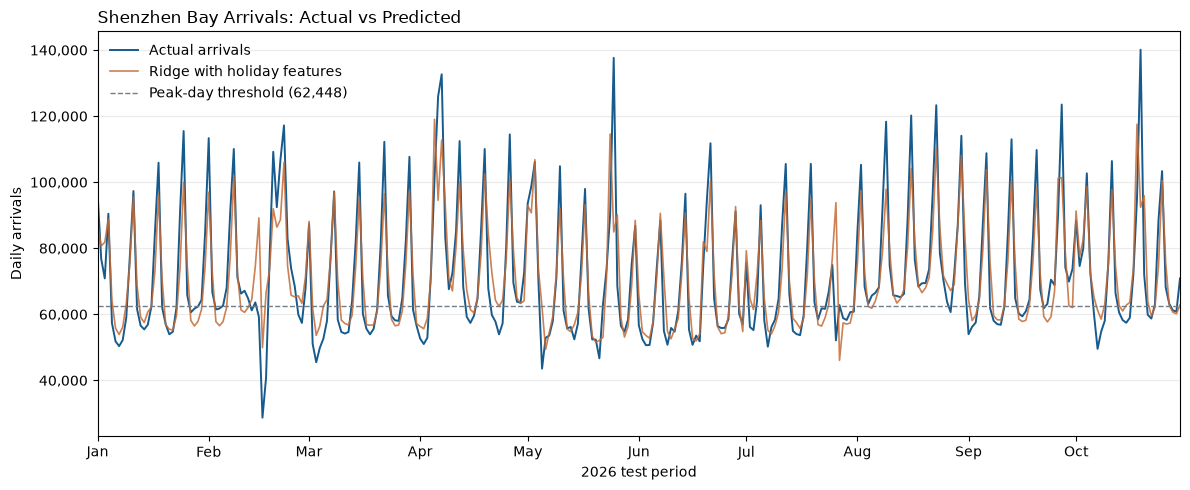

已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\test_predictions_2026.csv
已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\test_metrics_2026.csv
已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\figures\test_actual_vs_predicted_2026.png


In [16]:
# 保存逐日预测值和各组评价指标
results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

predictions_path = results_dir / "test_predictions_2026.csv"
metrics_path = results_dir / "test_metrics_2026.csv"

test_predictions.to_csv(
    predictions_path, index=False, date_format="%Y-%m-%d"
)
test_metrics.to_csv(metrics_path, index=False, encoding="utf-8-sig")

# 绘制主模型的实际值与预测值
plot_data = test_predictions.sort_values("date")
main_model_name = "Ridge (with holidays)"

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    plot_data["date"], plot_data["actual_arrivals"],
    color="#175A8C", linewidth=1.4, label="Actual arrivals",
)
ax.plot(
    plot_data["date"], plot_data[main_model_name],
    color="#C46A35", linewidth=1.2, alpha=0.85,
    label="Ridge with holiday features",
)
ax.axhline(
    peak_threshold, color="#737D87", linestyle="--", linewidth=1,
    label=f"Peak-day threshold ({peak_threshold:,.0f})",
)

ax.set_title("Shenzhen Bay Arrivals: Actual vs Predicted", loc="left")
ax.set_xlabel("2026 test period")
ax.set_ylabel("Daily arrivals")
ax.set_xlim(plot_data["date"].min(), plot_data["date"].max())
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()

test_figure_path = figures_dir / "test_actual_vs_predicted_2026.png"
fig.savefig(test_figure_path, dpi=300, bbox_inches="tight")
plt.show()

for path in [predictions_path, metrics_path, test_figure_path]:
    print("已保存", path)

## 第十六步：检查高峰日低估案例

In [17]:
ridge_with = "Ridge (with holidays)"
ridge_without = "Ridge (without holidays)"

case_data = test_predictions[
    ["date", "actual_arrivals", ridge_without, ridge_with]
].copy()

case_data["shortfall_without_holidays"] = (
    case_data["actual_arrivals"] - case_data[ridge_without]
).clip(lower=0)

case_data["shortfall_with_holidays"] = (
    case_data["actual_arrivals"] - case_data[ridge_with]
).clip(lower=0)

case_data["absolute_error_reduction"] = (
    (case_data["actual_arrivals"] - case_data[ridge_without]).abs()
    - (case_data["actual_arrivals"] - case_data[ridge_with]).abs()
)

# 只在实际客流达到固定阈值的日期中，选出主模型低估最多的五天
peak_cases = (
    case_data.loc[case_data["actual_arrivals"].ge(peak_threshold)]
    .nlargest(5, "shortfall_with_holidays")
    .merge(
        test_data[["date", *holiday_columns]],
        on="date",
        how="left",
        validate="one_to_one",
    )
)

display(peak_cases.round(0))

cases_path = results_dir / "peak_underprediction_cases_2026.csv"
peak_cases.to_csv(cases_path, index=False, date_format="%Y-%m-%d")
print("已保存", cases_path)

C:\Users\wy\AppData\Local\Temp\ipykernel_1544\1723873226.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(peak_cases.round(0))


,date,actual_arrivals,Ridge (without holidays),Ridge (with holidays),shortfall_without_holidays,shortfall_with_holidays,absolute_error_reduction,is_hk_holiday,is_cn_holiday
0,2026-05-25,137625,63223.0,84942.0,74402.0,52683.0,21719.0,1,0
1,2026-10-19,140103,71080.0,92418.0,69023.0,47685.0,21338.0,1,0
2,2026-04-06,125957,71196.0,94525.0,54761.0,31432.0,23329.0,1,1
3,2026-09-27,123505,100672.0,101391.0,22833.0,22114.0,719.0,0,0
4,2026-08-09,118320,96746.0,97864.0,21574.0,20456.0,1119.0,0,0


已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\peak_underprediction_cases_2026.csv


## 第十七步：保存验证结果汇总

In [18]:
validation_tables = {
    "validation_model_comparison_2025.csv": validation_comparison,
    "validation_holiday_comparison_2025.csv": holiday_comparison,
    "validation_peak_comparison_2025.csv": peak_comparison,
}

for filename, table in validation_tables.items():
    output_path = results_dir / filename
    table.to_csv(output_path, index=False, encoding="utf-8-sig")
    print("已保存", output_path)

已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\validation_model_comparison_2025.csv
已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\validation_holiday_comparison_2025.csv
已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\validation_peak_comparison_2025.csv


## 第十八步：分析高峰案例的旅客构成

In [19]:
# 包含前五个低估案例，保留 8 月 9 日供对照
case_dates = pd.to_datetime([
    "2026-05-25", "2026-10-19", "2026-04-06",
    "2026-09-27", "2026-08-09",
])

arrivals_by_date = daily_arrivals.set_index("date").sort_index()

traveller_types = {
    "hong_kong_residents": "香港居民",
    "mainland_visitors": "内地访客",
    "other_visitors": "其他访客",
}

case_rows = []

for day in case_dates:
    previous_same_weekdays = [
        day - pd.Timedelta(weeks=weeks) for weeks in range(1, 5)
    ]
    actual = arrivals_by_date.loc[day]
    recent = arrivals_by_date.loc[previous_same_weekdays]

    for column, traveller_type in traveller_types.items():
        typical = recent[column].median()
        increase = actual[column] - typical

        case_rows.append({
            "日期": day.strftime("%Y-%m-%d"),
            "旅客类别": traveller_type,
            "当天入境人次": actual[column],
            "此前四周同星期中位数": typical,
            "增加人次": increase,
            "增幅（%）": 100 * increase / typical if typical > 0 else float("nan"),
            "占当天总客流（%）": 100 * actual[column] / actual["total_arrivals"],
        })

traveller_case_summary = pd.DataFrame(case_rows)
display(traveller_case_summary.round(1))

composition_path = results_dir / "peak_case_traveller_composition_2026.csv"
traveller_case_summary.to_csv(composition_path, index=False, encoding="utf-8-sig")
print("已保存", composition_path)

,日期,旅客类别,当天入境人次,此前四周同星期中位数,增加人次,增幅（%）,占当天总客流（%）
0,2026-05-25,香港居民,124251,46677.5,77573.5,166.2,90.3
1,2026-05-25,内地访客,12107,15189.5,-3082.5,-20.3,8.8
2,2026-05-25,其他访客,1267,1561.0,-294.0,-18.8,0.9
3,2026-10-19,香港居民,121513,49597.5,71915.5,145.0,86.7
4,2026-10-19,内地访客,14259,16906.5,-2647.5,-15.7,10.2
5,2026-10-19,其他访客,4331,1558.0,2773.0,178.0,3.1
6,2026-04-06,香港居民,112557,47110.0,65447.0,138.9,89.4
7,2026-04-06,内地访客,11762,12089.0,-327.0,-2.7,9.3
8,2026-04-06,其他访客,1638,1494.0,144.0,9.6,1.3
9,2026-09-27,香港居民,103552,92962.5,10589.5,11.4,83.8


已保存 d:\course\ds and ai\shenzhen-bay-passenger-forecast\results\peak_case_traveller_composition_2026.csv
